In [55]:
from os import read

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy.stats import shapiro
from sklearn.model_selection import train_test_split

from statsmodels.stats.outliers_influence import variance_inflation_factor


In [8]:
data = pd.read_csv('./data/fastfood.csv', na_values=[',',' ',''])
display(data.head())

,restaurant,item,calories,cal_fat,total_fat,sat_fat,trans_fat,cholesterol,sodium,total_carb,fiber,sugar,protein,calcium
0,Mcdonalds,Artisan Grilled Chicken Sandwich,380,60.0,7,2.0,0.0,95,1110,44,3.0,11,37.0,20.0
1,Mcdonalds,Single Bacon Smokehouse Burger,840,410.0,45,17.0,1.5,130,1580,62,2.0,18,46.0,20.0
2,Mcdonalds,Double Bacon Smokehouse Burger,1130,600.0,67,27.0,3.0,220,1920,63,3.0,18,70.0,50.0
3,Mcdonalds,Grilled Bacon Smokehouse Chicken Sandwich,750,280.0,31,10.0,0.5,155,1940,62,2.0,18,55.0,20.0
4,Mcdonalds,Crispy Bacon Smokehouse Chicken Sandwich,920,410.0,45,12.0,0.5,120,1980,81,4.0,18,46.0,20.0


In [9]:
data.isna().sum()

restaurant       1
item             0
calories         0
cal_fat          1
total_fat        0
sat_fat          0
trans_fat        0
cholesterol      0
sodium           0
total_carb       0
fiber           12
sugar            0
protein          2
calcium        210
dtype: int64

In [11]:
data_sub= data.loc[data['total_fat'] <= 125].copy()
print(data_sub.head())


  restaurant                                       item  calories  cal_fat  \
0  Mcdonalds           Artisan Grilled Chicken Sandwich       380     60.0   
1  Mcdonalds             Single Bacon Smokehouse Burger       840    410.0   
2  Mcdonalds             Double Bacon Smokehouse Burger      1130    600.0   
3  Mcdonalds  Grilled Bacon Smokehouse Chicken Sandwich       750    280.0   
4  Mcdonalds   Crispy Bacon Smokehouse Chicken Sandwich       920    410.0   

   total_fat  sat_fat  trans_fat  cholesterol  sodium  total_carb  fiber  \
0          7      2.0        0.0           95    1110          44    3.0   
1         45     17.0        1.5          130    1580          62    2.0   
2         67     27.0        3.0          220    1920          63    3.0   
3         31     10.0        0.5          155    1940          62    2.0   
4         45     12.0        0.5          120    1980          81    4.0   

   sugar  protein  calcium  
0     11     37.0     20.0  
1     18     46.

In [12]:
print(f"Broj redova data_sub:{len(data_sub)}")
print(f"Broj redova data:{len(data)}")

Broj redova data_sub:513
Broj redova data:515


In [88]:
print(data_sub.isna().sum())

calories       0
cal_fat        0
total_fat      0
sat_fat        0
trans_fat      0
cholesterol    0
sodium         0
total_carb     0
fiber          0
sugar          0
protein        0
dtype: int64


In [18]:
p_s= shapiro(data_sub['cal_fat'].dropna())[1]
print(p_s)

m_s=data_sub['cal_fat'].median()
print(m_s)

data_sub['cal_fat']=data_sub['cal_fat'].fillna(m_s)
data_sub.isna().sum()

restaurant       1
item             0
calories         0
cal_fat          0
total_fat        0
sat_fat          0
trans_fat        0
cholesterol      0
sodium           0
total_carb       0
fiber           12
sugar            0
protein          2
calcium        209
dtype: int64

In [64]:
print(data_sub.isna().sum())

calories         0
cal_fat          0
total_fat        0
sat_fat          0
trans_fat        0
cholesterol      0
sodium           0
total_carb       0
fiber           12
sugar            0
protein          2
calcium        209
dtype: int64


In [65]:
data_sub.drop(columns='calcium', inplace=True)

In [66]:
print(data_sub.isna().sum())


calories        0
cal_fat         0
total_fat       0
sat_fat         0
trans_fat       0
cholesterol     0
sodium          0
total_carb      0
fiber          12
sugar           0
protein         2
dtype: int64


In [67]:
m_p=data_sub['protein'].median()
m_f=data_sub['fiber'].median()

data_sub['fiber']=data_sub['fiber'].fillna(m_f)
data_sub['protein']=data_sub['protein'].fillna(m_p)

print(data_sub.isna().sum())

calories       0
cal_fat        0
total_fat      0
sat_fat        0
trans_fat      0
cholesterol    0
sodium         0
total_carb     0
fiber          0
sugar          0
protein        0
dtype: int64


In [23]:
data_sub.drop(columns='restaurant', inplace=True)

In [24]:
display(data_sub.head())

,item,calories,cal_fat,total_fat,sat_fat,trans_fat,cholesterol,sodium,total_carb,fiber,sugar,protein,calcium
0,Artisan Grilled Chicken Sandwich,380,60.0,7,2.0,0.0,95,1110,44,3.0,11,37.0,20.0
1,Single Bacon Smokehouse Burger,840,410.0,45,17.0,1.5,130,1580,62,2.0,18,46.0,20.0
2,Double Bacon Smokehouse Burger,1130,600.0,67,27.0,3.0,220,1920,63,3.0,18,70.0,50.0
3,Grilled Bacon Smokehouse Chicken Sandwich,750,280.0,31,10.0,0.5,155,1940,62,2.0,18,55.0,20.0
4,Crispy Bacon Smokehouse Chicken Sandwich,920,410.0,45,12.0,0.5,120,1980,81,4.0,18,46.0,20.0


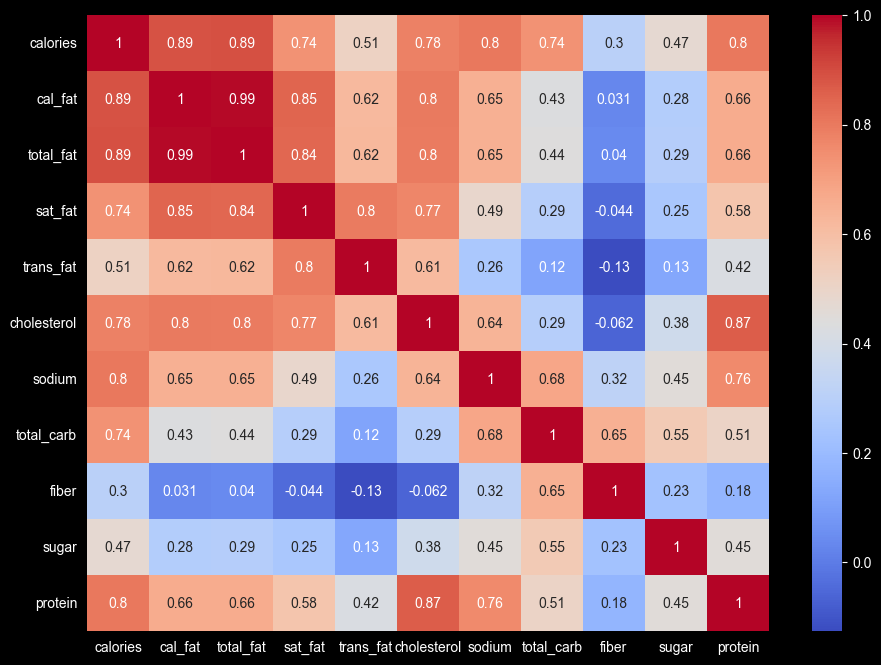

In [68]:
corr = data_sub.corr(numeric_only=True).round(4)
plt.figure(figsize=(11,8))
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.show()

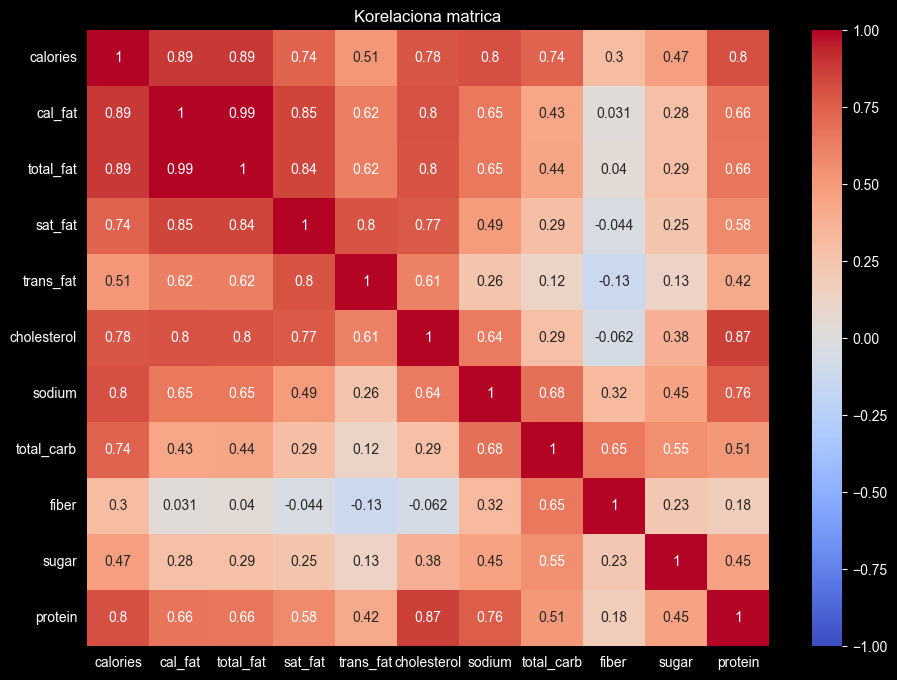

In [76]:
kor = data_sub.corr(numeric_only=True).round(4)
plt.figure(figsize=(11,8))
sns.heatmap(kor, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title('Korelaciona matrica')
plt.show()


In [ ]:
plt.figure(figsize=(11,8))
sns.heatmap(data.corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.show()

In [77]:
target = 'protein'
features = ['sodium','cholesterol','calories']

In [79]:
target1 = 'calories'
features1 = ['cal_fat','total_fat']

In [80]:
train_c,test_c = train_test_split(data_sub,test_size=0.2,random_state=42)
print(f"Broj redova train:{len(train_c)}")
print(f"Broj redova test:{len(test_c)}")

Broj redova train:410
Broj redova test:103


In [81]:
lmc = smf.ols(f'{target1}~'+'+'.join(features1), data=train_c).fit()
print(lmc.summary())

                            OLS Regression Results                            
Dep. Variable:               calories   R-squared:                       0.785
Model:                            OLS   Adj. R-squared:                  0.784
Method:                 Least Squares   F-statistic:                     743.6
Date:                Tue, 16 Jun 2026   Prob (F-statistic):          1.24e-136
Time:                        17:47:22   Log-Likelihood:                -2551.6
No. Observations:                 410   AIC:                             5109.
Df Residuals:                     407   BIC:                             5121.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    166.3289     11.031     15.079      0.0

In [ ]:
lm = smf.ols(f'{target}~'+'+'.join(features1), data=train_c).fit()

In [84]:
X_test = test_c[['cal_fat','total_fat']]
y_test = test_c[target1]
y_pred = lmc.predict(X_test)
res = pd.DataFrame({
    'Stvarno':y_test.values,
    'Predvidjeno':y_pred.round(2),
})
display(res.head(10))

,Stvarno,Predvidjeno
306,430,409.61
498,470,466.06
441,340,409.61
154,740,695.23
500,270,358.53
132,320,409.61
206,260,302.08
509,700,573.59
327,410,386.76
249,470,423.72


In [78]:
train,test = train_test_split(data_sub, test_size=0.2, random_state=42)
print(f"Broj redova train:{len(train)}")
print(f"Broj redova test:{len(test)}")

Broj redova train:410
Broj redova test:103


In [44]:
lm1=smf.ols(f'{target} ~ '+'+'.join(features), data=train).fit()
print(lm1.summary())

                            OLS Regression Results                            
Dep. Variable:                protein   R-squared:                       1.000
Model:                            OLS   Adj. R-squared:                    nan
Method:                 Least Squares   F-statistic:                       nan
Date:                Tue, 16 Jun 2026   Prob (F-statistic):                nan
Time:                        16:47:53   Log-Likelihood:                 7000.1
No. Observations:                 242   AIC:                        -1.352e+04
Df Residuals:                       0   BIC:                        -1.267e+04
Df Model:                         241                                         
Covariance Type:            nonrobust                                         
                                                                             coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------

In [45]:
display(data_sub.info())

None

In [46]:
data_sub.drop(columns='item', inplace=True)
display(data_sub.info())

None

In [47]:
lm2 = smf.ols(f'{target}~'+'+'.join(features), data=train).fit()
print(lm2.summary())

                            OLS Regression Results                            
Dep. Variable:                protein   R-squared:                       0.831
Model:                            OLS   Adj. R-squared:                  0.829
Method:                 Least Squares   F-statistic:                     662.5
Date:                Tue, 16 Jun 2026   Prob (F-statistic):          9.16e-156
Time:                        16:50:40   Log-Likelihood:                -1320.0
No. Observations:                 409   AIC:                             2648.
Df Residuals:                     405   BIC:                             2664.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept       2.9751      0.696      4.273      

In [89]:
X_test = test[['cholesterol','calories','sodium']]
y_true = test['protein']
y_pred = lm2.predict(X_test)
results = pd.DataFrame({
    'Stvarno':y_true.values,
    'Predvidjeno':lm2.predict(X_test),
})
print(results.head(10))

     Stvarno  Predvidjeno
306     19.0    19.081214
498     13.0    17.540676
441     12.0    15.812984
154     49.0    47.688579
500     14.0    16.826517
132     11.0    17.924667
206     13.0    14.382451
509     23.0    25.500183
327     20.0    21.968150
249     37.0    27.582008


In [ ]:

# - Residuals vs Fitted -
# Grafikon prikazuje raspodelu reziduala (razlike između stvarnih i predviđenih vrednosti) u odnosu na predviđene vrednosti.
# Ovaj grafikon se koristi da proveri da li je zadovoljena pretpostavka linearne veze.
# Residuali bi trebalo da budu raspoređeni oko horizontalne linije (vrednost bliska nuli).
# Sa grafikona se može zaključiti da postoje manja odstupanja (nelineranost), što može ukazivati na neadekvatnost modela.

# - Normal Q-Q -
# Ovaj grafikon prikazuje da li reziduali imaju normalnu raspodelu.
# Tačke bi trebalo da leže duž dijagonale.
# Pošto tačke odstupaju od dijagonale na krajevima, pretpostavka normalnosti nije u potpunosti ispunjena.

# - Scale-Location -
# Prikazuje da li je varijabilnost (varijansa) reziduala konstantna duž predikcija.
# Idealno, crvena linija treba da bude horizontalna i da tačke budu ravnomerno raspoređene.
# U ovom slučaju, varijansa reziduala nije potpuno konstantna, što ukazuje na moguću heteroskedastičnost.

# - Residuals vs Leverage -
# Ovaj grafikon identifikuje ekstremno visoke/niske vrednosti (outliere) i njihove uticaje na model.
# Većina tačaka bi trebalo da bude unutar granica, a ekstremne vrednosti retke.
# Na osnovu Cookove distance vidi se da postoji nekoliko potencijalnih outliera, što može uticati na stabilnost modela.

In [57]:
#VIF
X = sm.add_constant(train[features])
vif = pd.Series([variance_inflation_factor(X.values,i) for i in range(X.shape[1])], index=X.columns)
print('VIF prve verzije:\n', np.sqrt(vif))

VIF prve verzije:
 const          2.299495
sodium         1.666079
cholesterol    1.587883
calories       2.064371
dtype: float64


In [58]:
lmf = smf.ols(f'{target}~ cholesterol + sodium', data=train).fit()

In [60]:
X = sm.add_constant(train[['cholesterol','sodium']])
vif = pd.Series([variance_inflation_factor(X.values,i) for i in range(X.shape[1])], index=X.columns)
print('VIF druge verzije:\n', np.sqrt(vif))

VIF druge verzije:
 const          2.187006
cholesterol    1.281450
sodium         1.281450
dtype: float64


In [87]:
X = sm.add_constant(train[features1])
vif1 = pd.Series([variance_inflation_factor(X.values,i) for i in range(X.shape[1])],index=X.columns)
print('VIF prve verzije:\n', np.sqrt(vif1))

VIF prve verzije:
 const        1.823082
cal_fat      9.696039
total_fat    9.696039
dtype: float64
